# MediBuddy Insurance Charges Analysis

## Objective
Explore how customer characteristics relate to recorded insurance charges, then build and evaluate a model to predict charges.

In [ ]:
import pandas as pd

personal = pd.read_excel(
    "data/Medibuddy insurance data personal details (1) (2).xlsx"
)

price = pd.read_excel(
    "data/Medibuddy Insurance Data Price (1) (2).xlsx"
)

print("Personal details file:", personal.shape)
print("Price file:", price.shape)



Personal details file: (1338, 4)
Price file: (1338, 5)


In [ ]:
# Combine the files using the policy number
combined = personal.merge(
    price,
    on="Policy no.",
    how="inner",
    validate="one_to_one"
)

print("Combined rows and columns:", combined.shape)
print("\nMissing values in each column:")
print(combined.isna().sum())
print("\nDuplicate policy numbers:", combined["Policy no."].duplicated().sum())



Combined rows and columns: (1338, 8)

Missing values in each column:
Policy no.        0
children          0
smoker            0
region            0
age               0
sex               0
bmi               0
charges in INR    0
dtype: int64

Duplicate policy numbers: 0


## Exploratory Analysis

We compare recorded charges across the customer characteristics in the assignment.

In [3]:
average_charge = combined["charges in INR"].mean()
median_charge = combined["charges in INR"].median()

print("Average charge per policy (INR):", round(average_charge, 2))
print("Median charge per policy (INR):", round(median_charge, 2))

Average charge per policy (INR): 13270.42
Median charge per policy (INR): 9382.03


In [4]:
combined.groupby("sex")["charges in INR"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
sex,,,
female,662,12569.58,9412.96
male,676,13956.75,9369.62


In [5]:
combined.groupby("region")["charges in INR"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
region,,,
northeast,324,13406.38,10057.65
northwest,325,12417.58,8965.80
southeast,364,14735.41,9294.13
southwest,325,12346.94,8798.59


In [6]:
combined.groupby("children")["charges in INR"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
children,,,
0,574,12365.98,9856.95
1,324,12731.17,8483.87
2,240,15073.56,9264.98
3,157,15355.32,10600.55
4,25,13850.66,11033.66
5,18,8786.04,8589.57


In [7]:
combined.groupby("smoker")["charges in INR"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
smoker,,,
no,1064,8434.27,7345.41
yes,274,32050.23,34456.35


In [8]:
combined["age_group"] = pd.cut(
    combined["age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-64"]
)

combined.groupby("age_group", observed=False)["charges in INR"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
age_group,,,
18-25,306,9087.02,2636.02
26-35,268,10495.16,4900.58
36-45,264,13493.49,7442.57
46-55,284,15986.90,10477.96
56-64,216,18795.99,13429.65


In [9]:
combined["bmi_group"] = pd.cut(
    combined["bmi"],
    bins=[0, 18.5, 25, 30, 100],
    labels=["Below 18.5", "18.5-25", "25-30", "30+"]
)

combined.groupby("bmi_group", observed=False)["charges in INR"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
bmi_group,,,
Below 18.5,21,8657.62,6640.54
18.5-25,226,10435.44,8604.15
25-30,386,10997.80,8659.38
30+,705,15560.93,9964.06


In [10]:
from sklearn.model_selection import train_test_split

X = combined[["age", "sex", "bmi", "children", "smoker", "region"]]
y = combined["charges in INR"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 1070
Testing rows: 268


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score

categorical = ["sex", "smoker", "region"]

preprocess = ColumnTransformer(
    [("categories", OneHotEncoder(handle_unknown="ignore"), categorical)],
    remainder="passthrough"
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

baseline = DummyRegressor(strategy="mean")

forest = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(n_estimators=300, random_state=42))
])

baseline_mae = -cross_val_score(
    baseline, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error"
)

forest_mae = -cross_val_score(
    forest, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error"
)

print("Baseline average MAE (INR):", round(baseline_mae.mean(), 2))
print("Random Forest average MAE (INR):", round(forest_mae.mean(), 2))

Baseline average MAE (INR): 9119.43
Random Forest average MAE (INR): 2697.36


In [12]:
from sklearn.model_selection import RandomizedSearchCV

parameters = {
    "model__n_estimators": [150, 250, 400],
    "model__max_depth": [None, 5, 8, 12],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [1.0, 0.8, "sqrt"]
}

search = RandomizedSearchCV(
    forest,
    param_distributions=parameters,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_

print("Best cross-validation MAE (INR):", round(-search.best_score_, 2))
print("Best settings:", search.best_params_)

Best cross-validation MAE (INR): 2505.88
Best settings: {'model__n_estimators': 150, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 0.8, 'model__max_depth': 5}


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

test_predictions = best_model.predict(X_test)

mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
r2 = r2_score(y_test, test_predictions)

print("Test MAE (INR):", round(mae, 2))
print("Test RMSE (INR):", round(rmse, 2))
print("Test R-squared:", round(r2, 3))

Test MAE (INR): 2388.31
Test RMSE (INR): 4401.78
Test R-squared: 0.864


In [14]:
feature_names = best_model.named_steps["preprocess"].get_feature_names_out()
importances = best_model.named_steps["model"].feature_importances_

pd.Series(importances, index=feature_names).sort_values(ascending=False)

categories__smoker_yes          0.371720
categories__smoker_no           0.341579
remainder__bmi                  0.156102
remainder__age                  0.115219
remainder__children             0.009214
categories__region_northeast    0.002071
categories__region_northwest    0.001161
categories__region_southeast    0.001138
categories__region_southwest    0.000655
categories__sex_male            0.000644
categories__sex_female          0.000498
dtype: float64

## Conclusions and Recommendations

The two files were joined using Policy no. The combined dataset contained 1,338 policies, with no missing values or duplicate policy numbers.

### Analysis findings

- **Average charge:** The mean recorded charge was ₹13,270.42 per policy; the median was ₹9,382.03.
- **Gender:** Male average charges were ₹13,956.75 and female average charges were ₹12,569.58. Their medians were nearly the same. This dataset alone does not support using gender as a policy restriction.
- **Region:** The southeast had the highest average charge at ₹14,735.41. The other regional averages ranged from about ₹12,300 to ₹13,400. This variation may merit monitoring, but it does not by itself establish a need for separate policies.
- **Children:** Charges did not increase steadily with the number of children. The groups with four and five children were small, so their averages are less reliable.
- **Smoking:** Average charges were ₹32,050.23 for smokers and ₹8,434.27 for non-smokers. Smoking status was strongly associated with higher recorded charges.
- **Age:** Average and median charges increased across the age groups, from 18–25 to 56–64.
- **BMI:** The BMI 30+ group had the highest average charge at ₹15,560.93. BMI alone does not predict an individual charge, and this comparison alone is not enough to recommend BMI-based discounts.

These are patterns in this dataset; they do not by themselves establish causes or determine appropriate policy terms.

### Prediction model

A Random Forest regression model was trained using age, sex, BMI, number of children, smoking status, and region. The data was split into 1,070 training records and 268 test records. Five-fold cross-validation and randomized hyperparameter search were used on the training set.

The tuned model's cross-validation MAE was ₹2,505.88. On the held-out test set, it achieved:

- **MAE:** ₹2,388.31
- **RMSE:** ₹4,401.78
- **R-squared:** 0.864

The test MAE means predictions were off by about ₹2,388 on average in this test split. The higher RMSE indicates some larger individual errors. R-squared indicates the model explained about 86.4% of charge variation in this particular test set; future accuracy may differ.

The model relied most on smoking status, followed by BMI and age. Feature importance describes the model's use of these fields; it does not show that they cause charges.

Matplotlib is building the font cache; this may take a moment.


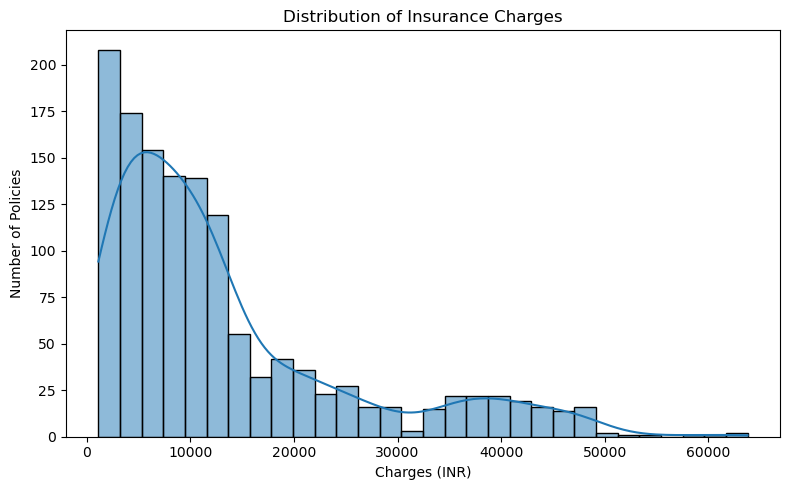

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(data=combined, x="charges in INR", bins=30, kde=True)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Charges (INR)")
plt.ylabel("Number of Policies")
plt.tight_layout()
plt.show()

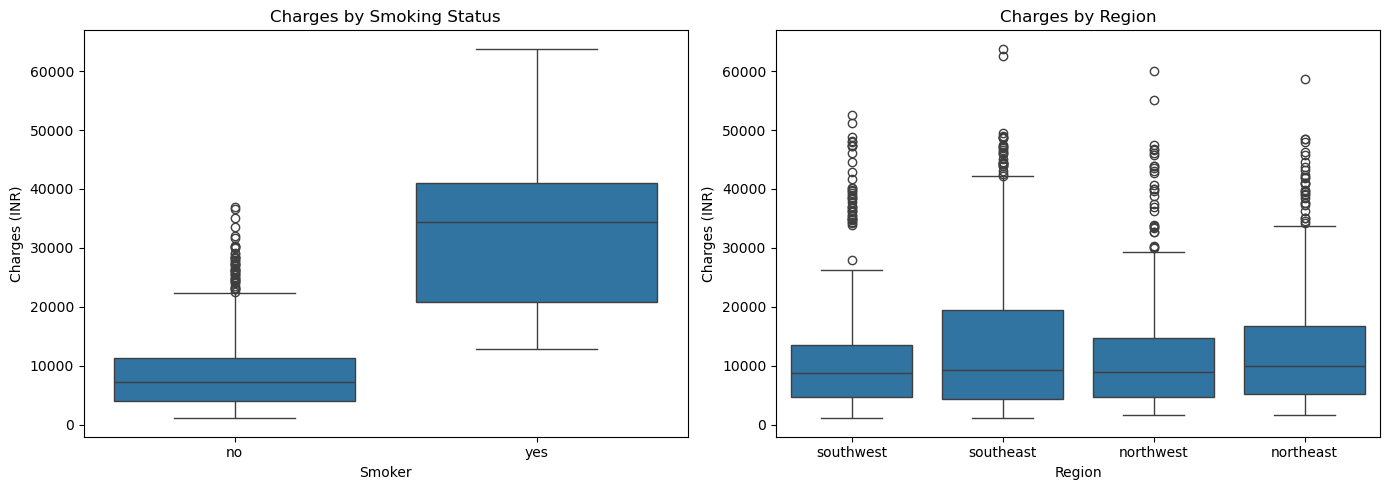

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=combined, x="smoker", y="charges in INR", ax=axes[0])
axes[0].set_title("Charges by Smoking Status")
axes[0].set_xlabel("Smoker")
axes[0].set_ylabel("Charges (INR)")

sns.boxplot(data=combined, x="region", y="charges in INR", ax=axes[1])
axes[1].set_title("Charges by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Charges (INR)")

plt.tight_layout()
plt.show()

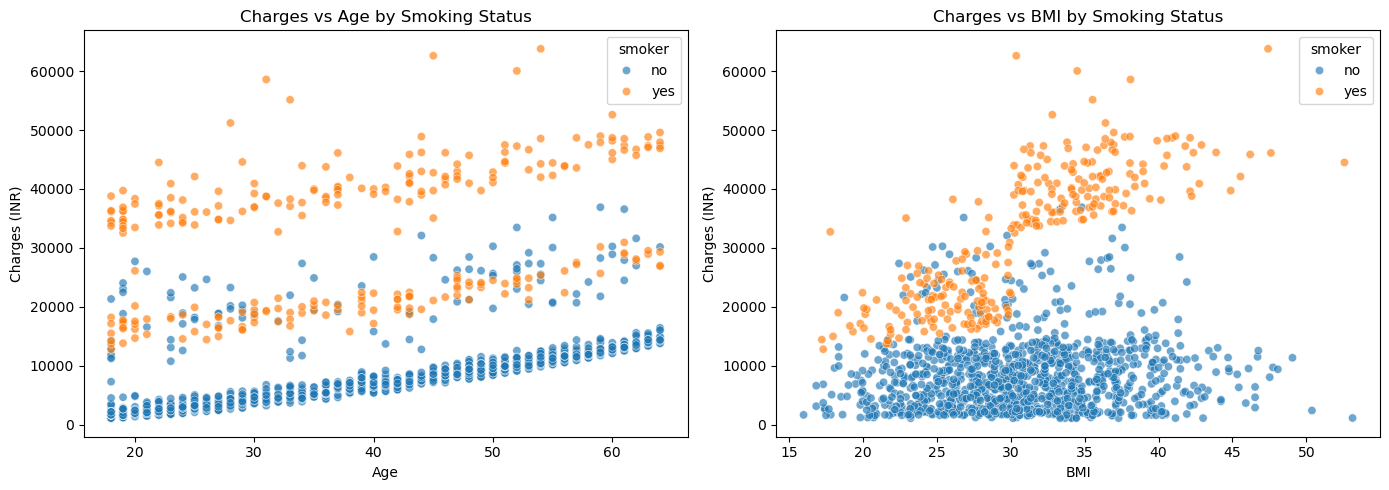

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=combined, x="age", y="charges in INR",
    hue="smoker", alpha=0.65, ax=axes[0]
)
axes[0].set_title("Charges vs Age by Smoking Status")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Charges (INR)")

sns.scatterplot(
    data=combined, x="bmi", y="charges in INR",
    hue="smoker", alpha=0.65, ax=axes[1]
)
axes[1].set_title("Charges vs BMI by Smoking Status")
axes[1].set_xlabel("BMI")
axes[1].set_ylabel("Charges (INR)")

plt.tight_layout()
plt.show()

In [25]:
from scipy.stats import mannwhitneyu, kruskal

female = combined.loc[combined["sex"] == "female", "charges in INR"]
male = combined.loc[combined["sex"] == "male", "charges in INR"]

non_smokers = combined.loc[combined["smoker"] == "no", "charges in INR"]
smokers = combined.loc[combined["smoker"] == "yes", "charges in INR"]

region_groups = [
    combined.loc[combined["region"] == region, "charges in INR"]
    for region in combined["region"].unique()
]

print("Gender test p-value:",
      mannwhitneyu(female, male, alternative="two-sided").pvalue)

print("Smoking test p-value:",
      mannwhitneyu(non_smokers, smokers, alternative="two-sided").pvalue)

print("Region test p-value:",
      kruskal(*region_groups).pvalue)

Gender test p-value: 0.7286510894470093
Smoking test p-value: 5.270233444503571e-130
Region test p-value: 0.19232908072121002


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline

linear_model = Pipeline([
    ("preprocess", preprocess),
    ("model", TransformedTargetRegressor(
        regressor=LinearRegression(),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

linear_mae = -cross_val_score(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

print("Log-linear average CV MAE (INR):", round(linear_mae.mean(), 2))

Log-linear average CV MAE (INR): 4242.21


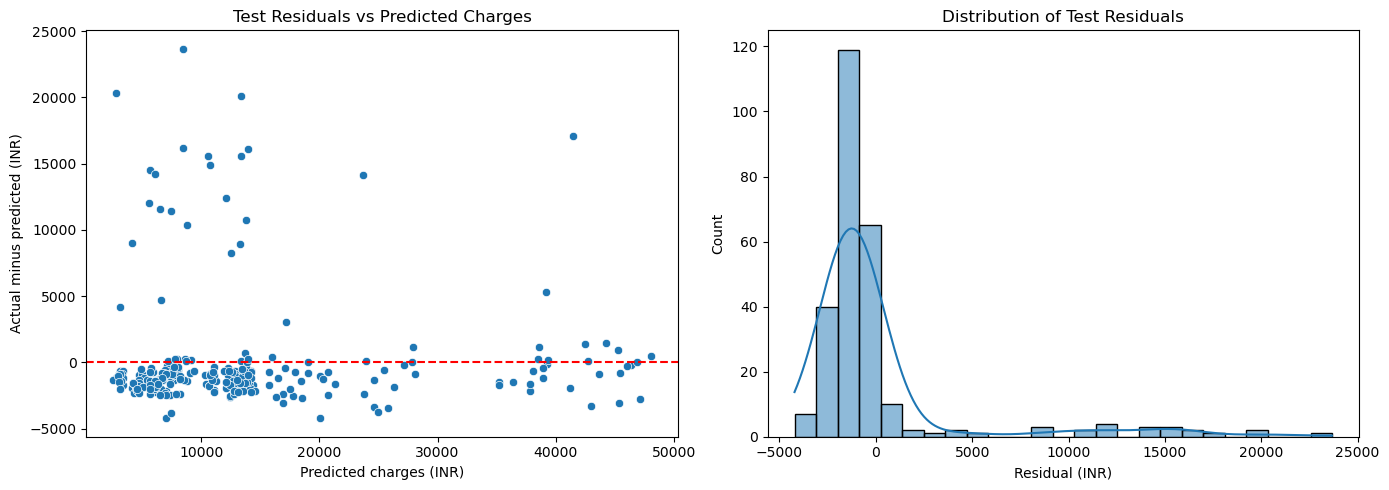

In [27]:
residuals = y_test - test_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=test_predictions, y=residuals, ax=axes[0])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Test Residuals vs Predicted Charges")
axes[0].set_xlabel("Predicted charges (INR)")
axes[0].set_ylabel("Actual minus predicted (INR)")

sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Test Residuals")
axes[1].set_xlabel("Residual (INR)")

plt.tight_layout()
plt.show()

In [29]:
combined["bmi_group"] = pd.cut(
    combined["bmi"],
    bins=[0, 18.5, 25, 30, 100],
    labels=["Below 18.5", "18.5-25", "25-30", "30+"]
)

combined.groupby(
    ["bmi_group", "smoker"], observed=False
)["charges in INR"].agg(
    ["count", "mean", "median"]
).round(2)

count      mean    median
bmi_group  smoker                           
Below 18.5 no         16   5485.06   4249.32
           yes         5  18809.82  15006.58
18.5-25    no        176   7734.65   6669.48
           yes        50  19942.22  19479.90
25-30      no        311   8226.09   7046.72
           yes        75  22491.18  21348.71
30+        no        561   8853.28   8083.92
           yes       144  41692.81  40918.31

In [30]:
print("Column types:")
print(combined.dtypes)

print("\nNumeric value ranges:")
print(combined[["age", "bmi", "children", "charges in INR"]].describe().round(2))

print("\nPossible outliers by the 1.5 × IQR rule:")
for column in ["age", "bmi", "children", "charges in INR"]:
    q1 = combined[column].quantile(0.25)
    q3 = combined[column].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((combined[column] < low) | (combined[column] > high)).sum()
    print(column, ":", count)

Column types:
Policy no.          object
children             int64
smoker              object
region              object
age                  int64
sex                 object
bmi                float64
charges in INR     float64
bmi_group         category
dtype: object

Numeric value ranges:
           age      bmi  children  charges in INR
count  1338.00  1338.00   1338.00         1338.00
mean     39.21    30.66      1.09        13270.42
std      14.05     6.10      1.21        12110.01
min      18.00    15.96      0.00         1121.87
25%      27.00    26.30      0.00         4740.29
50%      39.00    30.40      1.00         9382.03
75%      51.00    34.69      2.00        16639.91
max      64.00    53.13      5.00        63770.43

Possible outliers by the 1.5 × IQR rule:
age : 0
bmi : 9
children : 0
charges in INR : 139
